# SECOM 半導體測試未通過預測與 SHAP 解釋

用量測欄位預測產線測試的 Pass/Fail，並說明模型在不同個案的判斷。各節可依序重新執行。圖表採英文標籤以相容常見字型。

## 1. 讀取與稽核
UCI 將每列定義為一個生產個體，標籤 1 為未通過、-1 為通過。CSV 的 590 個量測欄位以編號表示。時間只用於排序與切分，因為它是測試時間。缺值指空白或讀取後的 NaN。重複以整列完全一致計算。

In [1]:
from pathlib import Path
from itertools import combinations
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, confusion_matrix, PrecisionRecallDisplay

CSV_PATH = Path('uci-secom.csv')
if not CSV_PATH.is_file():
    CSV_PATH = Path.home() / 'Downloads' / 'uci-secom.csv'
raw = pd.read_csv(CSV_PATH)
X = raw.drop(columns=['Time', 'Pass/Fail'])
assert set(raw['Pass/Fail']) == {-1, 1}
y = raw['Pass/Fail'].eq(1).astype(int)
missing = X.isna().mean()
print(f'筆數 {len(X)}｜量測欄位 {X.shape[1]}｜未通過 {y.sum()} ({y.mean():.2%})')
print(f'缺值格數 {X.isna().sum().sum()}｜缺值過半欄位 {(missing > .5).sum()}')
print(f'常數欄位 {X.nunique().eq(1).sum()}｜完全重複列 {raw.duplicated().sum()}')

筆數 1567｜量測欄位 590｜未通過 104 (6.64%)
缺值格數 41951｜缺值過半欄位 28
常數欄位 116｜完全重複列 0


## 2. 修正時間並以日期切分
CSV 有部分日期月日對調。原始 UCI 標籤前幾筆日期是 2008 年 7 月 19 日，而在 CSV 中顯示為 2008-02-09 的一段，在原始標籤對應 2008 年 9 月 2 日。假設原始檔列序為時間非遞減，每列保留正常與互換兩種合法日期，由前往後選最早、由後往前選最晚。如果兩次得到同一組日期，代表在這個假設下解唯一。同一時間戳可以有多筆測試。

以 9 月 1 日與 9 月 29 日為界，保留完整日期，依序作為訓練、驗證、測試。訓練建模，驗證選模型與門檻，最後才用測試集量化表現。圖中每週分母不同，筆數圖可和比率圖一起看。

[UCI 原始標籤檔](https://archive.ics.uci.edu/ml/machine-learning-databases/secom/secom_labels.data)

修正 582 筆｜2008-07-19 11:55:00 至 2008-10-17 06:07:00
訓練 618 筆，未通過 65 筆 (10.52%)
驗證 548 筆，未通過 15 筆 (2.74%)
測試 401 筆，未通過 24 筆 (5.99%)


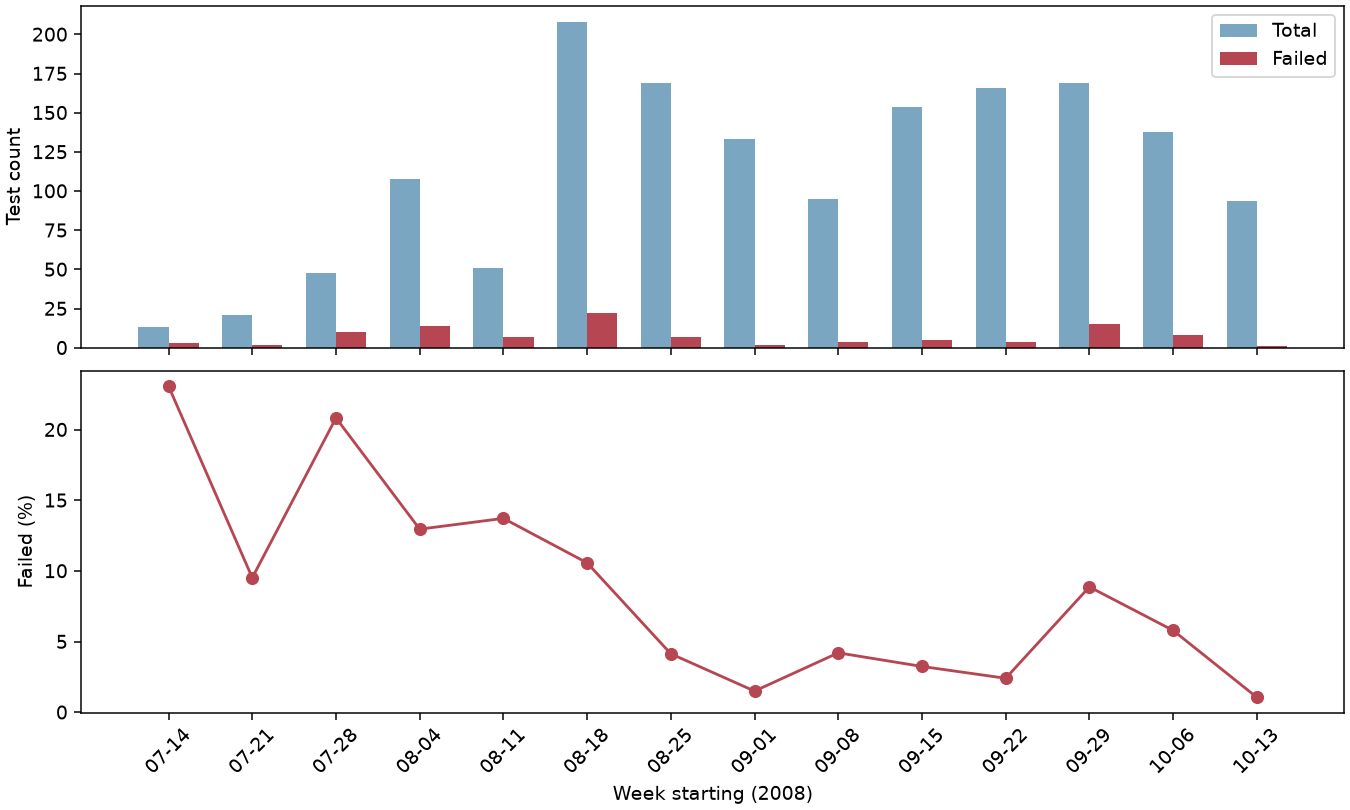

In [2]:
def recover_dates(values):
    iso = pd.to_datetime(values, format='%Y-%m-%d %H:%M:%S')
    swapped = pd.to_datetime(values, format='%Y-%d-%m %H:%M:%S', errors='coerce')
    candidates = list(zip(iso, swapped))
    earliest, latest = [], []
    for pair in candidates:
        earliest.append(min(t for t in pair if pd.notna(t) and (not earliest or t >= earliest[-1])))
    for pair in reversed(candidates):
        latest.append(max(t for t in pair if pd.notna(t) and (not latest or t <= latest[-1])))
    if earliest != latest[::-1]:
        raise ValueError('日期有多種解，請用 UCI 原始標籤核對。')
    return pd.Series(earliest, index=values.index), iso

time, iso = recover_dates(raw['Time'])
train = time < '2008-09-01'
test = time >= '2008-09-29'
valid = ~(train | test)
print(f'修正 {(time != iso).sum()} 筆｜{time.min()} 至 {time.max()}')
for name, mask in [('訓練', train), ('驗證', valid), ('測試', test)]:
    assert y[mask].nunique() == 2
    print(f'{name} {mask.sum()} 筆，未通過 {y[mask].sum()} 筆 ({y[mask].mean():.2%})')

weekly = y.groupby(time.dt.to_period('W')).agg(total='size', failed='sum')
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
weeks = np.arange(len(weekly))
axes[0].bar(weeks - .18, weekly.total, width=.36, color='#7aa6c2', label='Total')
axes[0].bar(weeks + .18, weekly.failed, width=.36, color='#b74653', label='Failed')
axes[0].legend()
axes[0].set(ylabel='Test count')
axes[1].plot(weeks, 100 * weekly.failed / weekly.total, marker='o', color='#b74653')
axes[1].set_xticks(weeks, [v.start_time.strftime('%m-%d') for v in weekly.index], rotation=45)
axes[1].set(xlabel='Week starting (2008)', ylabel='Failed (%)')
plt.show()

## 3. 建立基準並比較候選模型
只用訓練期統計，剔除缺值超過 50% 或至多一個有效值的欄位。模型用訓練中位數補值；邏輯迴歸再做標準化，讓不同量綱的欄位能使用同樣的正則化。常數基準對每一筆給相同分數，AP 等於當期未通過比例。邏輯迴歸用兩種正則化強度，決策樹比較深度 2 與 3，最小葉節點 20 筆，避免對少數樣本切出很小的葉。兩種模型皆使用類別權重；分數用於排序和判定，應避免直接當作校準後的失敗機率。

平均精確率 AP 衡量高分樣本中找到未通過的能力，綜合不同召回率下的精確率。用驗證 AP 選候選模型。

In [3]:
training_data = X.loc[train]
features = training_data.columns[training_data.isna().mean().le(.5) & training_data.nunique().gt(1)]
X = X[features]
models = {'Constant baseline': DummyClassifier(strategy='prior')}
for strength in (.01, .1):
    models[f'Logistic C={strength}'] = make_pipeline(
        SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(C=strength, class_weight='balanced', max_iter=1000)
    )
for depth in (2, 3):
    models[f'Tree depth={depth}'] = make_pipeline(
        SimpleImputer(strategy='median'),
        DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, class_weight='balanced', random_state=42)
    )
for model in models.values():
    model.fit(X.loc[train], y[train])

def score(model, frame):
    return model.predict_proba(frame)[:, 1]

validation_ap = pd.Series({
    name: average_precision_score(y[valid], score(model, X.loc[valid]))
    for name, model in models.items()
}).sort_values(ascending=False)
winner = validation_ap.drop('Constant baseline').idxmax()
model = models[winner]
print(f'保留 {len(features)} 個量測欄位')
print(validation_ap.round(4).to_string())
print(f'驗證選出的模型 {winner}')

保留 444 個量測欄位
Tree depth=3         0.0504
Tree depth=2         0.0485
Logistic C=0.01      0.0346
Logistic C=0.1       0.0306
Constant baseline    0.0274
驗證選出的模型 Tree depth=3


## 4. 選擇門檻並評估較晚的樣本
目前沒有指定現場可接受的誤報量，所以在驗證資料示範 5%、10%、20% 的誤報率上限。誤報率分母是實際通過筆數。各情境選擇可抓到最多未通過的最低可行門檻；同樣分數的樣本一起判定。預先以 10% 情境做主結果與 SHAP 個案分類。模型和門檻固定後才計算測試結果。測試誤報率可能超過驗證上限，因為兩期的資料分布可能不同。

測試 AP 0.0575｜常數基準 0.0599
 validation budget  threshold  validation FPR  TP  FP  FN  TN  recall    FPR
              0.05        inf          0.0000   0   0  24 377  0.0000 0.0000
              0.10     0.5864          0.0732   1  45  23 332  0.0417 0.1194
              0.20     0.5864          0.0732   1  45  23 332  0.0417 0.1194
主門檻混淆矩陣（列為實際、欄為預測，順序為通過／未通過）
[[332  45]
 [ 23   1]]


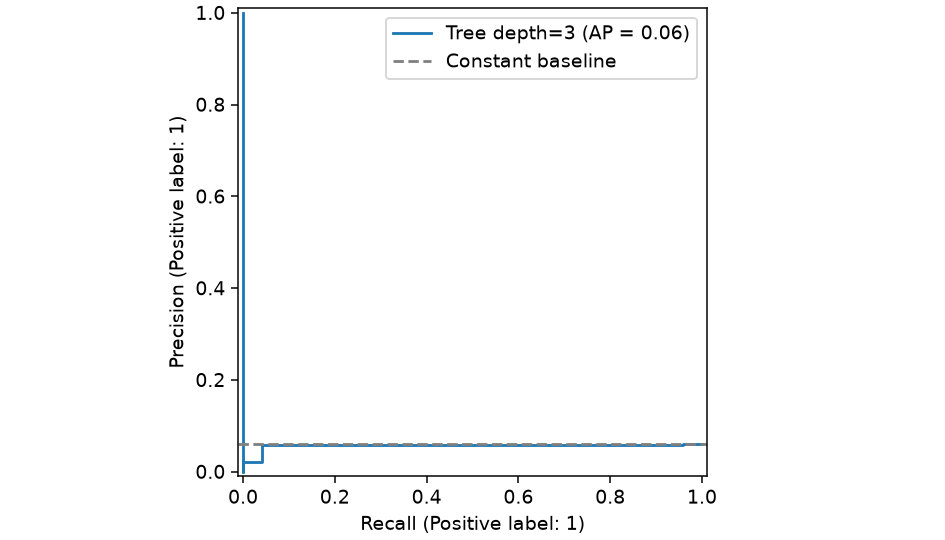

In [4]:
def counts(target, scores, threshold):
    tn, fp, fn, tp = confusion_matrix(target, scores >= threshold, labels=[0, 1]).ravel()
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, recall=tp / (tp + fn), FPR=fp / (fp + tn))

val_scores = score(model, X.loc[valid])
test_x, test_y = X.loc[test], y[test]
test_scores = score(model, test_x)
thresholds = {}
for budget in (.05, .10, .20):
    candidates = [*sorted(np.unique(val_scores)), np.inf]
    thresholds[budget] = next(t for t in candidates if counts(y[valid], val_scores, t)['FPR'] <= budget)

comparison = pd.DataFrame([
    {'validation budget': budget, 'threshold': t, 'validation FPR': counts(y[valid], val_scores, t)['FPR'],
     **counts(test_y, test_scores, t)}
    for budget, t in thresholds.items()
])
test_ap = average_precision_score(test_y, test_scores)
print(f'測試 AP {test_ap:.4f}｜常數基準 {test_y.mean():.4f}')
print(comparison.round(4).to_string(index=False))
threshold = thresholds[.10]
flags = test_scores >= threshold
print('主門檻混淆矩陣（列為實際、欄為預測，順序為通過／未通過）')
print(confusion_matrix(test_y, flags, labels=[0, 1]))
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
PrecisionRecallDisplay.from_predictions(test_y, test_scores, ax=ax, name=winner)
ax.axhline(test_y.mean(), linestyle='--', color='gray', label='Constant baseline')
ax.legend()
plt.show()

## 5. SHAP 如何計算
背景資料從訓練集抽 64 筆，固定亂數種子。基準是模型在這 64 筆的平均輸出。對特徵集合 S，保留該筆樣本的 S 欄位，其他欄位使用背景列，對預測取平均。SHAP 值是該欄位加入各種特徵集合後，讓預測變動的加權平均。

若選到邏輯迴歸，在對數勝算尺度上，模型是係數與標準化特徵的加總，SHAP 可直接用係數乘上「該筆特徵值與背景均值的差」。若選到淺層樹，最多有 7 個分裂欄位，可枚舉組合，直接計算未通過分數的 SHAP。兩種做法都對選定背景算出精確的介入式 SHAP，並檢查基準加上各欄貢獻等於每一筆的模型輸出。介入式填補可能形成製程中少見的欄位組合，相關欄位的個別排序須審慎解讀。

[SHAP 原始論文](https://proceedings.neurips.cc/paper_files/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html)

加總驗證 401 筆｜最大殘差 1.11e-16
59     0.149547
144    0.080257
41     0.060092
64     0.023105
390    0.019311


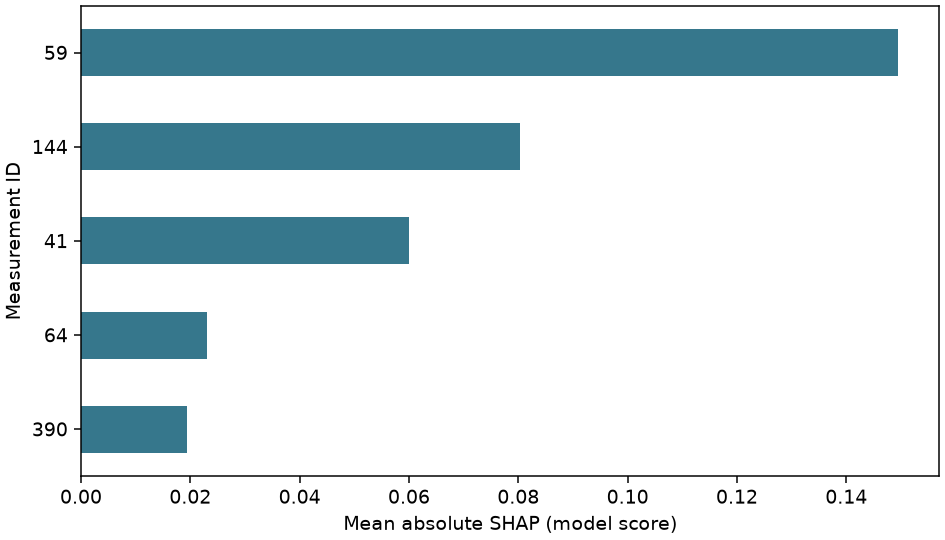

In [5]:
transform = model[:-1]
estimator = model[-1]
background = transform.transform(X.loc[train].sample(n=64, random_state=42))
samples = transform.transform(test_x)
if isinstance(estimator, LogisticRegression):
    baseline = estimator.decision_function(background).mean()
    shap_values = (samples - background.mean(axis=0)) * estimator.coef_[0]
    outputs = estimator.decision_function(samples)
    units = 'log odds'
else:
    active = sorted(set(estimator.tree_.feature) - {-2})
    players = len(active)
    values = {}
    for size in range(players + 1):
        for subset in combinations(active, size):
            hybrid = np.broadcast_to(background, (len(samples), *background.shape)).copy()
            for column in subset:
                hybrid[:, :, column] = samples[:, column, None]
            predictions = estimator.predict_proba(hybrid.reshape(-1, samples.shape[1]))[:, 1]
            values[frozenset(subset)] = predictions.reshape(len(samples), -1).mean(axis=1)
    baseline = values[frozenset()][0]
    shap_values = np.zeros_like(samples)
    for column in active:
        for subset, value in values.items():
            if column not in subset:
                weight = 1 / (players * comb(players - 1, len(subset)))
                shap_values[:, column] += weight * (values[subset | {column}] - value)
    outputs = score(model, test_x)
    units = 'model score'

error = np.abs(baseline + shap_values.sum(axis=1) - outputs)
assert np.all(error < 1e-9)
print(f'加總驗證 {len(samples)} 筆｜最大殘差 {error.max():.3g}')
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=features)
top = importance[importance > 1e-12].nlargest(12)
print(top.head(5).to_string())
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
top.iloc[::-1].plot.barh(ax=ax, color='#36778c')
ax.set(xlabel=f'Mean absolute SHAP ({units})', ylabel='Measurement ID')
plt.show()

## 6. 逐筆解讀抓到、誤報和漏報
同一種案例選最靠近門檻的一筆，讓讀者看到判定邊界附近的個案；如果某類沒有樣本，就直接回報。瀑布圖由基準開始，紅色推高模型輸出，藍色拉低。顯示貢獻絕對值最大的六欄，其他欄合併成一條。星號代表原資料缺值，模型使用訓練中位數。解釋針對模型判斷，推論製程根因需要量測欄位的定義及量測時間。

True positive｜CSV 第 1445 列｜2008-10-09 15:55:00｜分數 0.5864
主要貢獻 {'41': 0.3424, '144': -0.1456, '59': 0.0387, '64': -0.0124, '390': 0.0112}
False positive｜CSV 第 1203 列｜2008-09-30 17:27:00｜分數 0.5864
主要貢獻 {'41': 0.3424, '144': -0.1456, '59': 0.0387, '64': -0.0124, '390': 0.0112}
False negative｜CSV 第 1187 列｜2008-09-29 21:48:00｜分數 0.0885
主要貢獻 {'144': -0.1456, '59': -0.0742, '41': -0.0311, '64': -0.0241, '390': 0.0112}


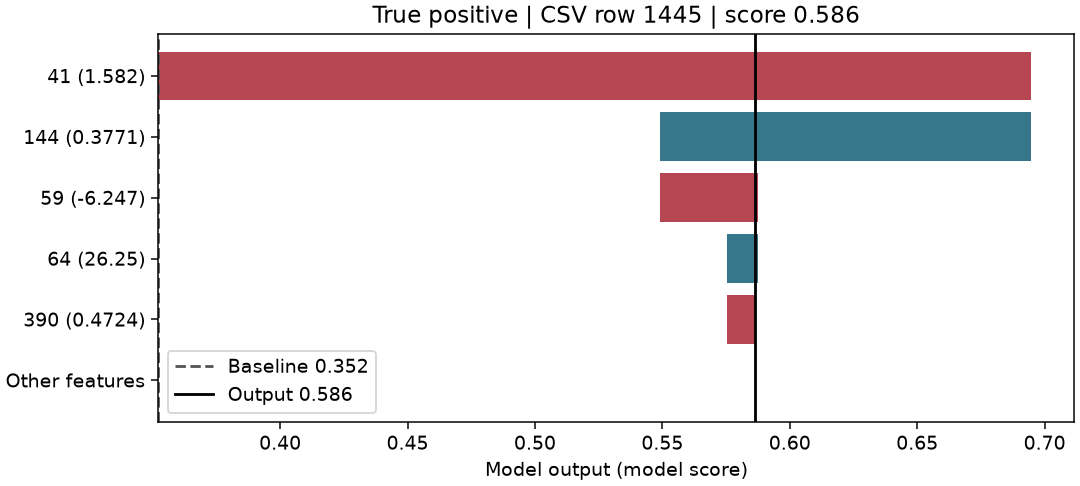

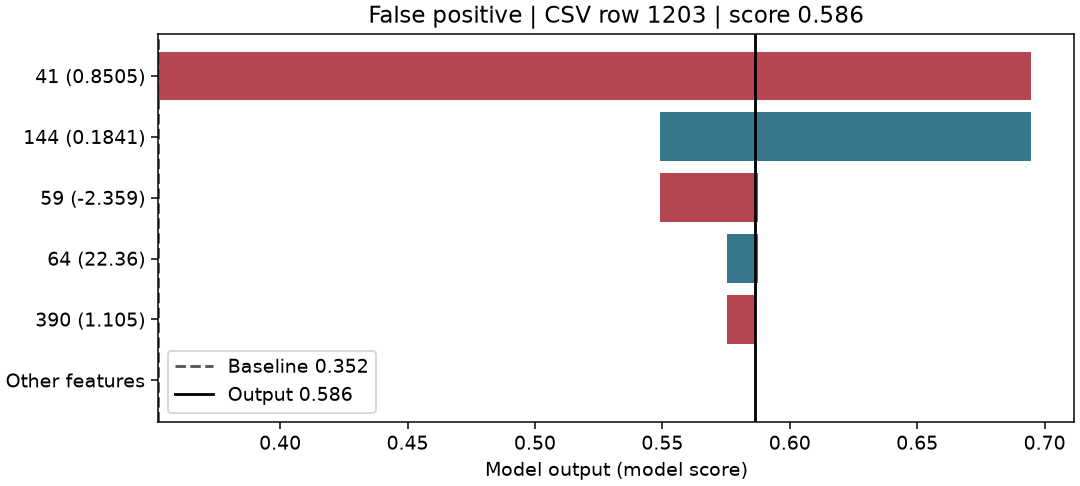

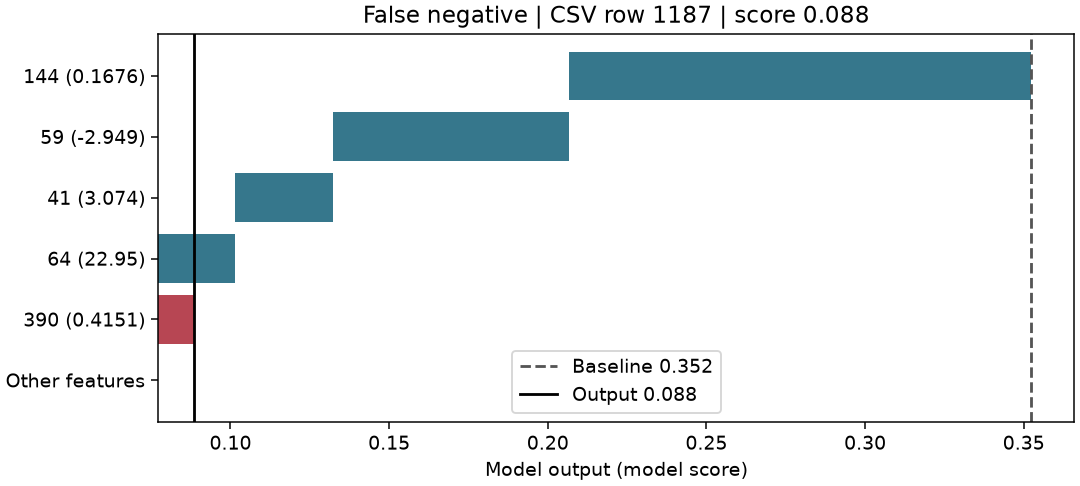

In [6]:
for label, mask in [('True positive', flags & test_y.eq(1)), ('False positive', flags & test_y.eq(0)),
                    ('False negative', ~flags & test_y.eq(1))]:
    positions = np.flatnonzero(mask)
    if not len(positions):
        print(f'{label}：主門檻無此類案例')
        continue
    i = positions[np.argmin(abs(test_scores[positions] - threshold))]
    row = test_x.iloc[i]
    phi = pd.Series(shap_values[i], index=features)
    nonzero = phi[phi.abs() > 1e-12]
    shown = nonzero.loc[nonzero.abs().nlargest(6).index]
    contributions = list(shown) + [phi.sum() - shown.sum()]
    labels = [f'{c} ({row[c]:.4g})' if pd.notna(row[c]) else f'{c} (missing*)' for c in shown.index] + ['Other features']
    starts = baseline + np.r_[0., np.cumsum(contributions)[:-1]]
    ends = starts + contributions
    fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
    ax.barh(labels, np.abs(contributions), left=np.minimum(starts, ends),
            color=np.where(np.asarray(contributions) >= 0, '#b74653', '#36778c'))
    ax.axvline(baseline, color='#555555', ls='--', label=f'Baseline {baseline:.3f}')
    ax.axvline(outputs[i], color='black', label=f'Output {outputs[i]:.3f}')
    ax.set(title=f'{label} | CSV row {row.name + 2} | score {test_scores[i]:.3f}',
           xlabel=f'Model output ({units})')
    ax.invert_yaxis()
    ax.legend(loc='best')
    print(f'{label}｜CSV 第 {row.name + 2} 列｜{time.loc[row.name]}｜分數 {test_scores[i]:.4f}')
    print('主要貢獻', shown.round(4).to_dict())
    plt.show()

## 7. 判讀與重現
請把測試期結果視為一次歷史回測。只有 24 筆測試未通過，單筆會改變召回率約 4.2 個百分點。欄位篩選與補值皆從訓練期取得，但測試前實際可取得哪些欄位仍待確認。中位數填補可能掩蓋缺值訊號，瀑布圖上的缺值標示僅供個案解讀。若要把結果用於未來的製程，需有新的時間區段來檢驗表現。

資料來源為 McCann 和 Johnston 的 [UCI SECOM](https://archive.ics.uci.edu/dataset/179/secom)，CSV 為 [Kaggle 版本](https://www.kaggle.com/datasets/paresh2047/uci-semcom/data)。